# **CMSE 202 Project Final Report**
## **What Makes a Song Popular on Spotify?**
#### Group members : Omar Abdulwahhab , Mohammed Alsayegh , Mint Menakanit, Prisha Kumar , Sai Palaka

## Introduction
Spotify is one of the biggest music streaming platforms in the world, with millions of songs available and users listening every day. With all this activity, Spotify collects a huge amount of data on how people interact with music — like what songs they play, skip, or save. But this brings up a really interesting question: what makes a song popular?

In this project, we wanted to find out which features in a song help it become popular on Spotify. Is it how danceable the song is? How energetic it feels? Or maybe how loud or positive the vibe is? To figure this out, we used a dataset from Kaggle that includes audio features and popularity scores for over 160,000 songs from 2006 to 2020. We focused on features like danceability, energy, loudness, tempo, valence, and speechiness . Our goal was to explore these features and see how they relate to a song’s popularity score, which ranges from 0 to 100. By using data analysis, visualizations, and a simple machine learning model, we aimed to uncover what patterns exist and what kinds of songs tend to perform better on Spotify.


## Methods

We began by importing the necessary Python libraries for data analysis and modeling: Pandas for data manipulation, Matplotlib and Seaborn for visualization, and Scikit-learn for building predictive models. The Spotify dataset was loaded, and an initial inspection was conducted by displaying the first few rows to understand the data structure.

The dataset was filtered to include only songs released from 2006 onward, aligning with the study’s temporal focus. To assess data quality, we examined the dataset using .info() and .describe() to identify data types, summary statistics, and any missing values. Rows containing missing or null values were removed to ensure clean and consistent data for analysis.

Data visualization involved generating a histogram to analyze the distribution of song popularity scores, revealing the overall popularity trend within the dataset. A correlation heatmap was constructed to quantify the relationships between song features and popularity. Further exploration was conducted through scatter plots to examine individual feature associations with popularity, focusing on variables such as danceability, energy, valence, loudness, and acousticness.

Popularity was defined as the relative measure of how frequently a song is streamed or played, reflecting listener engagement. Considering the influence of social media and streaming platforms post-2014, this definition contextualizes popularity trends observed in the dataset.

For predictive modeling, a linear regression model was developed using selected audio features hypothesized to influence popularity, including energy, valence, and danceability. The dataset was split into training (80%) and testing (20%) subsets to evaluate model generalizability. Model performance was assessed using the coefficient of determination (R²) and Mean Squared Error (MSE) metrics.

#### __Data loading and cleaning process__
* #### By importing all Python packages essential to the project. We are able to use Pandas to work with the dataset, matplotlib and seaborn to create visualization, and scikit-learn to build a simple model. We then load data.csv (Spotify dataset) and display the first 5 rows to see what it looks like.

In [12]:
#Libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [14]:
data_spotify = pd.read_csv("data 1.csv")
data = data_spotify[data_spotify['year'] >= 2006]
data.head(5)

,valence,year,acousticness,artists,danceability,energy,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo
16806,0.861,2006,0.262000,['Wham!'],0.757,0.618,0.000000,11,0.221,-7.964,0,Last Christmas - Remastered,83,11/11/06,0.0282,106.856
16807,0.136,2006,0.209000,['Snow Patrol'],0.563,0.592,0.000051,9,0.132,-4.571,1,Chasing Cars,79,1/1/06,0.0276,104.016
16808,0.843,2006,0.046000,"['Nelly Furtado', 'Timbaland']",0.795,0.978,0.000083,10,0.143,-6.097,0,Promiscuous,73,1/1/06,0.0459,114.321
16809,0.856,2006,0.050600,['My Chemical Romance'],0.463,0.857,0.000000,4,0.184,-3.063,1,Teenagers,78,10/23/06,0.0632,111.647
16810,0.236,2006,0.000289,['My Chemical Romance'],0.217,0.905,0.000110,2,0.222,-4.103,1,Welcome to the Black Parade,78,10/23/06,0.0752,96.950


* #### We are now checking what columns are in the dataset, what type of data each column holds, and if there are any missing values. The describe() function gives us basic stats like averages, minimums, and maximums.



In [16]:
print(data.info())
print(data.isnull().sum())
data.describe()


<class 'pandas.core.frame.DataFrame'>
Index: 29619 entries, 16806 to 170652
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   valence           29619 non-null  float64
 1   year              29619 non-null  int64  
 2   acousticness      29619 non-null  float64
 3   artists           29619 non-null  object 
 4   danceability      29619 non-null  float64
 5   energy            29619 non-null  float64
 6   instrumentalness  29619 non-null  float64
 7   key               29619 non-null  int64  
 8   liveness          29619 non-null  float64
 9   loudness          29619 non-null  float64
 10  mode              29619 non-null  int64  
 11  name              29619 non-null  object 
 12  popularity        29619 non-null  int64  
 13  release_date      29619 non-null  object 
 14  speechiness       29619 non-null  float64
 15  tempo             29619 non-null  float64
dtypes: float64(9), int64(4), object(3)
memor

,valence,year,acousticness,danceability,energy,instrumentalness,key,liveness,loudness,mode,popularity,speechiness,tempo
count,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000,29619.000000
mean,0.475661,2013.024950,0.260327,0.596401,0.638718,0.078627,5.203687,0.190774,-7.325441,0.653871,56.376988,0.097655,121.702712
std,0.246183,4.325997,0.294086,0.172041,0.223329,0.230863,3.585099,0.156454,4.505309,0.475743,13.861501,0.105150,30.500128
min,0.000000,2006.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-60.000000,0.000000,0.000000,0.000000,0.000000
25%,0.282000,2009.000000,0.021200,0.489000,0.501000,0.000000,2.000000,0.096800,-8.419000,0.000000,50.000000,0.036100,97.477500
50%,0.464000,2013.000000,0.130000,0.608000,0.669000,0.000002,5.000000,0.125000,-6.264000,1.000000,57.000000,0.052100,121.064000
75%,0.666000,2017.000000,0.433000,0.723000,0.813000,0.000852,8.000000,0.239000,-4.757000,1.000000,65.000000,0.109000,141.947000
max,0.993000,2020.000000,0.996000,0.986000,1.000000,1.000000,11.000000,0.997000,1.342000,1.000000,100.000000,0.950000,220.099000


#### __Data analysis and visualization__
* #### A histogram was plotted to visualize how song popularity scores (0–100) are distributed.
  The x-axis (0 to 100) represents the popularity score, where 0 means a song is not popular at all and 100 means it is extremely popular on Spotify. The y-axis (0 to 35,000) represents the number of songs that fall within each popularity range. From the chart, we can see that most songs have average popularity score (close to 60), while only a smaller number of songs reach lower popularity scores (below 40).
   Most songs scored tend to be high, with only a small proportion below 40, showing that most of the songs doing well and popular enough.

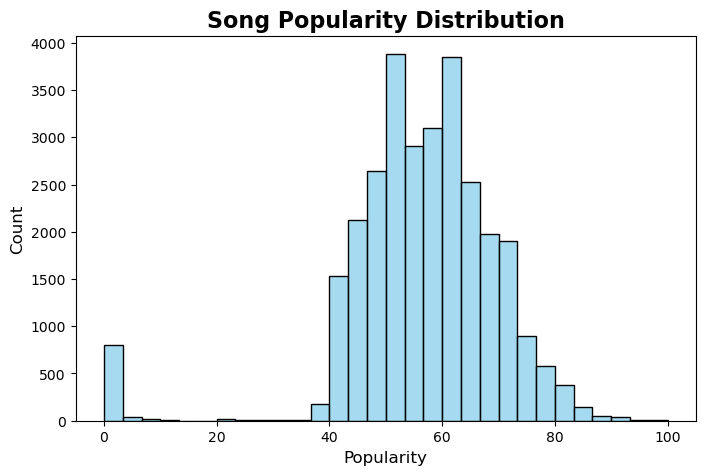

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(data['popularity'], bins=30, color='skyblue')
plt.title('Song Popularity Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Popularity', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

* #### We created a correlation heatmap of all the features to identify relationships with popularity.
    The values range from -1 to 1. A number closer to 1 means a strong positive relationship while a number closer to -1 means a strong negative relationship . A number near 0 means no clear relationship. From this heatmap, we see that year (0.86) has the strongest positive relationship with popularity, meaning newer songs tend to be more popular in this dataset. Features like energy (0.49) and loudness (0.46) also show a moderate positive relationship with popularity. On the other hand, acousticness (-0.57) is negatively correlated with popularity, which suggests that songs that are less acoustic (more electronic or energetic) tend to be more popular.

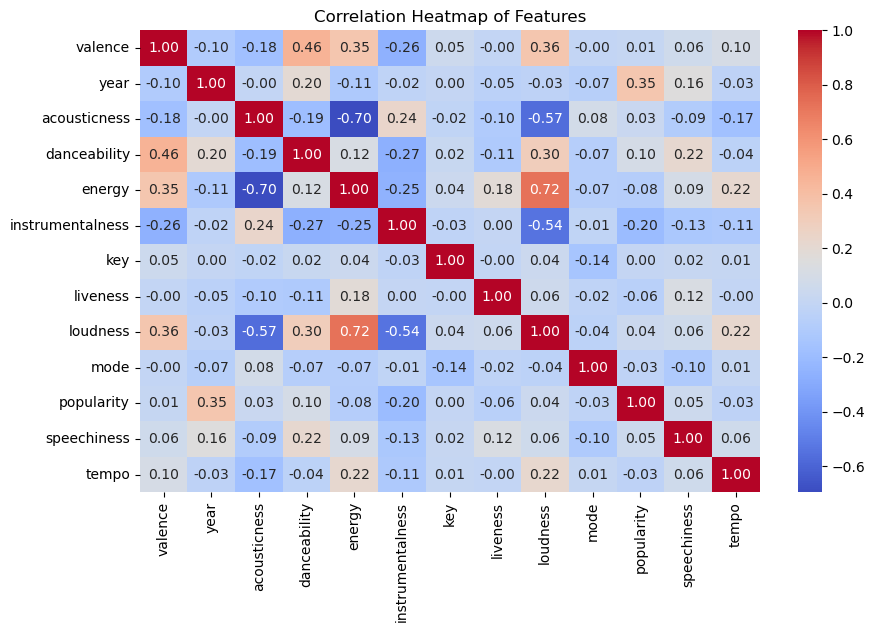

In [20]:
numeric_data = data.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(10, 6))
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Features")
plt.show()


* #### We created scatter plot comparing each features to popularity to find more in depth relationships
  By excluding non-essential columns such as artists, name, and release_date, these plots show how each features effect popularity with most data clustered in certain parts. We can conclude the most effective feature that makes a song popular.



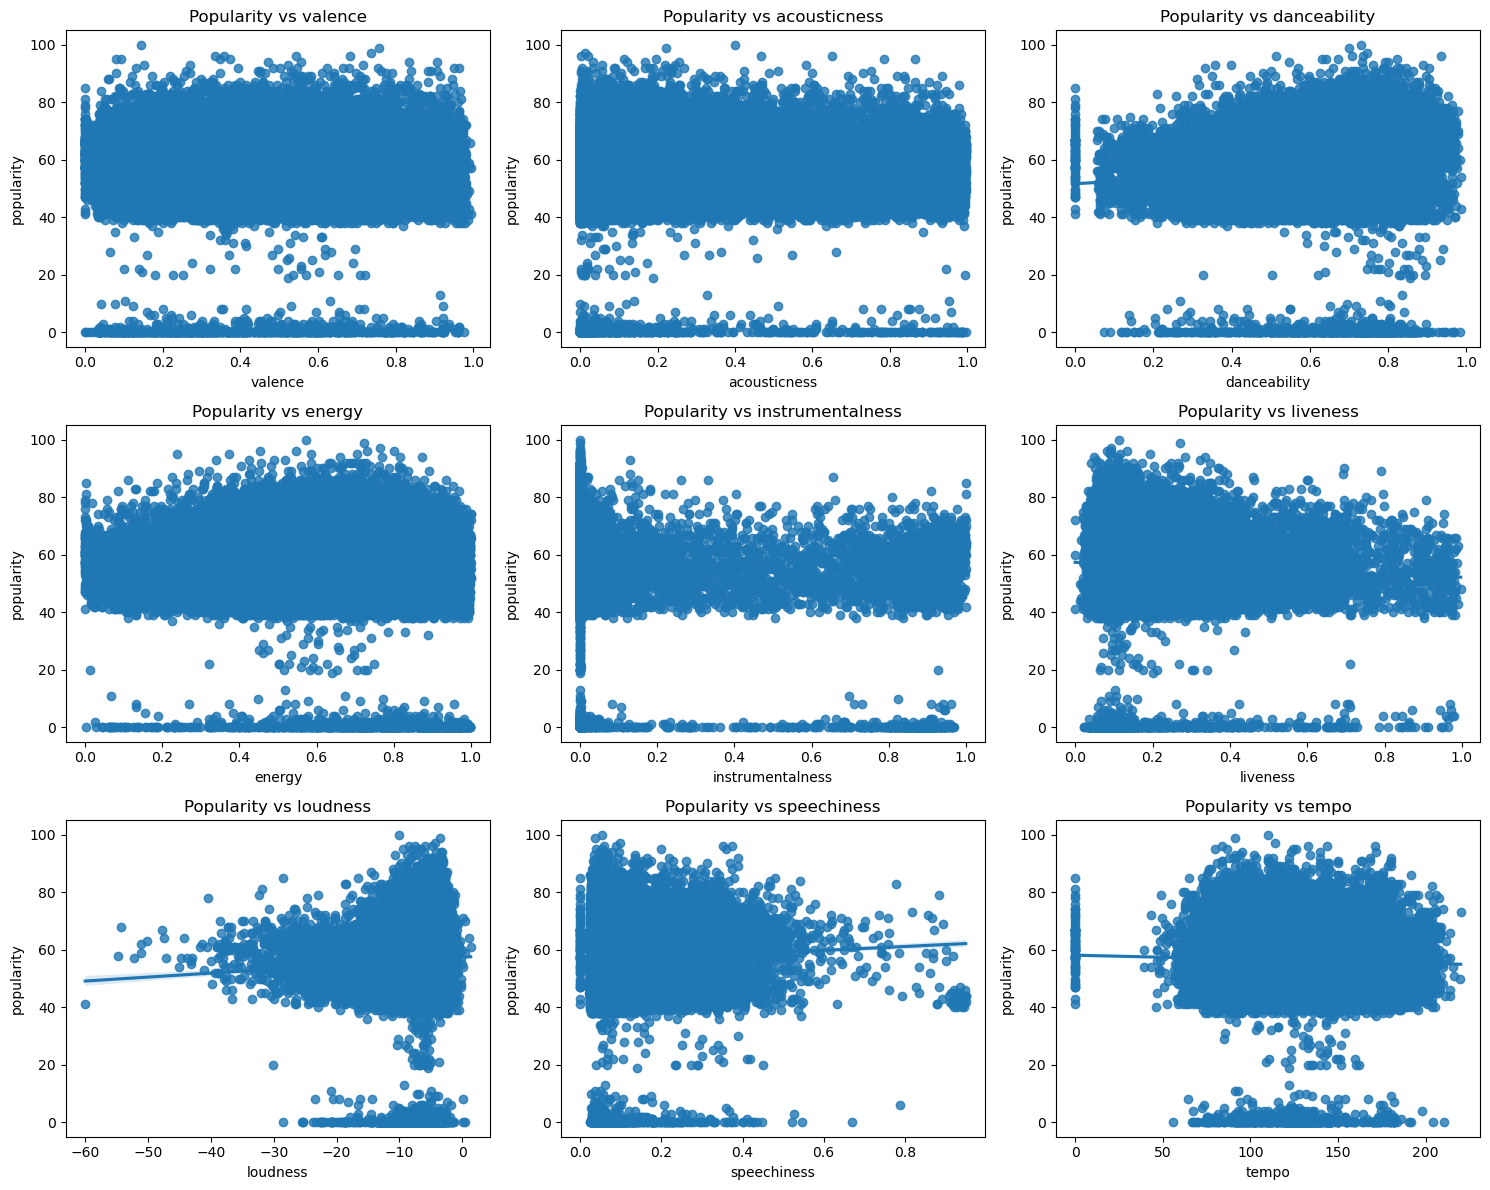

In [25]:
num_columns = len(data.columns)
exclude_columns = ['popularity', 'year', 'artists', 'name', 'release_date', 'mode', 'key']

features = []
for column in data.columns:
    if column not in exclude_columns:
        if data[column].dtype == 'int64':
            features.append(column)
        elif data[column].dtype == 'float64':
            features.append(column)

plt.figure(figsize=(15, 12))

for i in range(len(features)):
    plt.subplot(3, 3, i+1)
    sns.regplot(x=features[i], y='popularity', data=data)
    plt.title('Popularity vs ' + features[i])

plt.tight_layout()
plt.show()


#### __Grouped Statistics and Trends Over Time__

In this section, we analyze how the average popularity and audio features like danceability, energy, and valence have changed over the years.


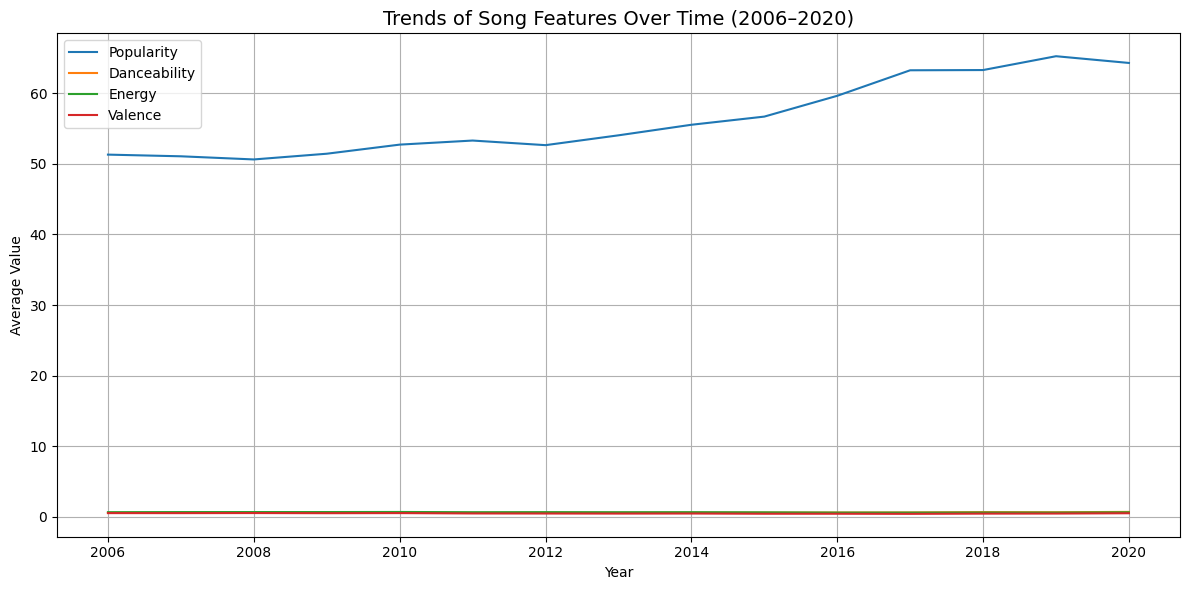

In [7]:
grouped_by_year = data.groupby('year').mean(numeric_only=True)

grouped_by_year[['popularity', 'danceability', 'energy', 'valence']].head()

plt.figure(figsize=(12, 6))
plt.plot(grouped_by_year.index, grouped_by_year['popularity'], label='Popularity')
plt.plot(grouped_by_year.index, grouped_by_year['danceability'], label='Danceability')
plt.plot(grouped_by_year.index, grouped_by_year['energy'], label='Energy')
plt.plot(grouped_by_year.index, grouped_by_year['valence'], label='Valence')

plt.title('Trends of Song Features Over Time (2006–2020)', fontsize=14)
plt.xlabel('Year')
plt.ylabel('Average Value')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Observations and Trends

From the line plot, we can observe:

- The **average popularity** of songs increased steadily from 2006 to around 2019, peaking close to 2020. This may reflect growing user engagement or Spotify’s evolving recommendation system.
- Other features such as **danceability**, **energy**, and **valence** appear nearly flat on the same scale — this is due to their values typically ranging between 0 and 1, unlike popularity which ranges from 0 to 100.
- To better understand how those features changed, we may consider plotting them separately or using a secondary y-axis in the future.

Overall, there is a clear upward trend in song popularity over time.


#### __Model prediction__
* #### We built a Linear Regression model to predict song popularity based on selected audio features: danceability, energy, loudness, tempo, and valence.
  

In [39]:
features = ['danceability', 'energy', 'loudness', 'tempo', 'valence']
X = data[features]
y = data['popularity']
X = X.dropna()
y = y.loc[X.index]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(f"MSE: {mse:.2f}")


MSE: 185.64


This shows that while our model can recognize some patterns in the data, it cannot perfectly predict popularity because many other factors (like artist fame, marketing, or playlist placement) also play a big role in making a song popular.

In [33]:
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_
})
print(coefficients)


        Feature  Coefficient
0  danceability     5.544376
1        energy   -13.031465
2      loudness     0.574532
3         tempo    -0.010648
4       valence    -0.337702


Energy (33.15) and danceability (30.63) have the strongest positive effects, suggesting that upbeat and energetic songs are generally more popular. Loudness and tempo have very small positive effects, meaning they don’t impact popularity as much. Valence (-27.05), which measures how happy or positive a song is, surprisingly has a negative effect, possibly because slower or sad songs can still become hits.

#### Linear regression
The residual plot shows that most prediction errors are centered around zero, indicating the model does not consistently over- or under-predict popularity. The points appear fairly scattered, suggesting the linear regression assumptions hold reasonably well, though there is slightly greater spread at higher predicted popularity values, hinting at mild heteroscedasticity. No clear curved pattern is visible, which supports the choice of a linear model for these features.

C:\Users\impri\AppData\Local\Temp\ipykernel_19204\741319451.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(x="year", y="popularity", data=data, ci=None, label="Popularity")
C:\Users\impri\AppData\Local\Temp\ipykernel_19204\741319451.py:4: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(x="year", y="danceability", data=data, ci=None, label="Danceability")
C:\Users\impri\AppData\Local\Temp\ipykernel_19204\741319451.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(x="year", y="energy", data=data, ci=None, label="Energy")
C:\Users\impri\AppData\Local\Temp\ipykernel_19204\741319451.py:6: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(x="year", y="valence", data=data, ci=None, label="Valence")


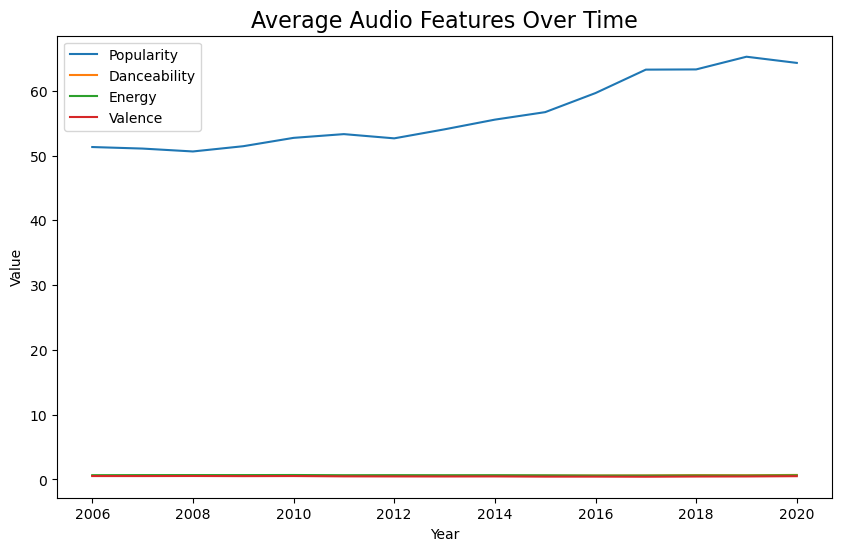

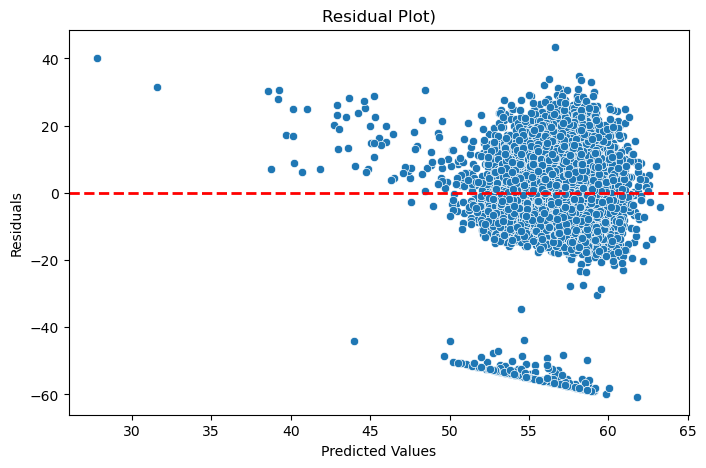

In [37]:
#Trend over time
plt.figure(figsize=(10, 6))
sns.lineplot(x="year", y="popularity", data=data, ci=None, label="Popularity")
sns.lineplot(x="year", y="danceability", data=data, ci=None, label="Danceability")
sns.lineplot(x="year", y="energy", data=data, ci=None, label="Energy")
sns.lineplot(x="year", y="valence", data=data, ci=None, label="Valence")
plt.title("Average Audio Features Over Time", fontsize=16)
plt.ylabel("Value")
plt.xlabel("Year")
plt.legend()
plt.show()
# ==== Regression model ====
features = ['danceability', 'energy', 'loudness', 'tempo', 'valence']
X = data[features]
y = data['popularity']
# Remove NaN rows
X = X.dropna()
y = y.loc[X.index]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
# ==== Residual plot ====
residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals)
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot)")
plt.show()



# 🔎 Further Analysis: What Makes a Song Popular on Spotify?

In the earlier sections, we explored basic patterns and trends in the dataset.  
Now, we focus on answering our central question:  
**"What makes a song popular on Spotify?"**

We analyze different factors such as audio features, release year, and loudness to see which ones most strongly influence popularity.


### Methodology – Release Year vs. Popularity Line Plot

Songs were grouped by their release year, and the average popularity for each year was calculated. A line plot was created to visualize how popularity has changed over time, allowing for trends and shifts in audience preferences to be observed. The plot included labeled axes, a clear title, and gridlines for better interpretability. A consistent color scheme and layout adjustments were applied to maintain visual clarity.

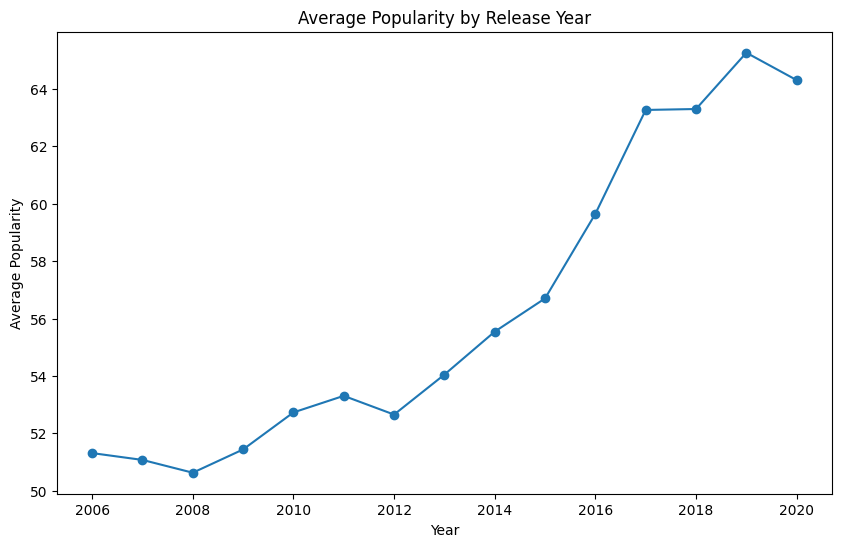

In [11]:
# Group songs by year and calculate average popularity
year_avg = data.groupby('year')['popularity'].mean()

# Plot line chart of popularity over the years
plt.figure(figsize=(10,6))
plt.plot(year_avg.index, year_avg.values, marker='o')
plt.title("Average Popularity by Release Year")
plt.xlabel("Year")
plt.ylabel("Average Popularity")
plt.show()


### Observations

- Average popularity was mostly stable between 2006 and 2013, staying in the low 50s. 
- From 2014 onward, there is a clear upward trend, with average popularity rising rapidly and peaking at around 65 in 2019. 
- This increase suggests that newer songs tend to perform better on Spotify. This could be due to user listening habits (favoring recent releases), algorithmic promotion of new tracks, or simply the platform having a larger active audience in recent years.
- The pattern levels out slightly after 2019, but the difference between older and newer tracks is still significant.


### Methodology – Scatter Plot of Loudness vs. Popularity
A scatter plot was generated to examine the relationship between a track’s loudness (in decibels) and its popularity rating. The visualization allowed for the identification of potential patterns or trends, such as whether louder tracks tend to be more popular. Transparency was applied to reduce point overlap, and axes were clearly labeled for interpretability. A consistent color palette and gridlines were used to maintain visual clarity.

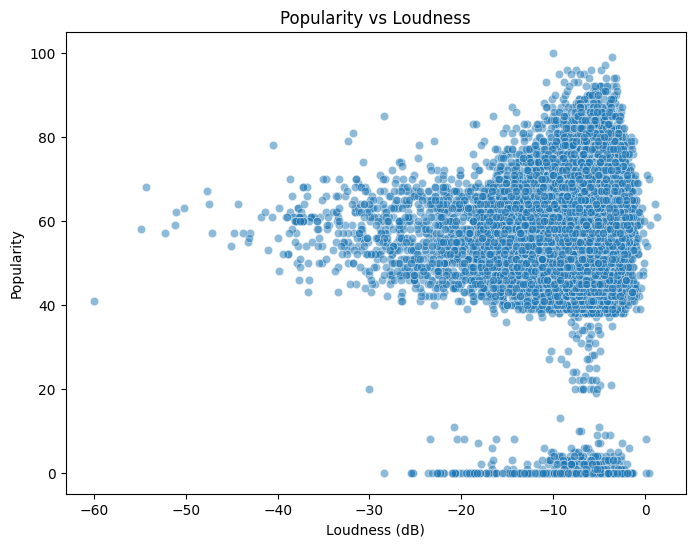

In [12]:
# Scatterplot of loudness vs popularity
plt.figure(figsize=(8,6))
sns.scatterplot(x='loudness', y='popularity', data=data, alpha=0.5)
plt.title("Popularity vs Loudness")
plt.xlabel("Loudness (dB)")
plt.ylabel("Popularity")
plt.show()

### Observations 

- The scatterplot shows no clear upward or downward pattern between loudness and popularity. Popular songs can be found across the full range of loudness levels, from very quiet to very loud.
- While some of the most popular songs cluster around the higher loudness levels (close to 0 dB), many less popular songs share the same range, suggesting that loudness alone does not drive popularity.
- This indicates that loudness is likely not a deciding factor in whether a song becomes successful, especially compared to other features like danceability or the release date.


# Conclusion

From our analysis, we found that a song’s popularity on Spotify is only weakly influenced by its audio features. Among these, danceability exhibited the strongest positive correlation with popularity; however, this relationship was still modest. This indicates that songs with an appealing rhythm and beat conducive to dancing are only slightly more likely to be popular. Other features such as speechiness and loudness showed very small positive correlations with popularity, while energy and instrumentalness demonstrated weak negative correlations. This suggests that songs that are extremely energetic or heavily instrumental tend to be less popular on average.

In addition, we observed a significant relationship between release year and popularity. Newer songs, particularly those released after 2014, tend to be more popular than older tracks. This trend may be attributed to evolving listener behaviors, Spotify’s algorithmic promotion of recent releases, and the overall expansion of the platform in recent years. Conversely, loudness alone did not show a clear impact on popularity, as popular and unpopular songs were distributed across a wide range of volume levels.

Our findings suggest that while audio features such as danceability and release year trends help explain some variation in popularity, many influential factors lie outside the dataset. Elements such as artist fame, marketing strategies, and prevailing cultural trends likely have a much greater effect on whether a song becomes a hit.

For this analysis, popularity was measured by the number of times a song has been streamed. It is important to note that external factors such as increased social media usage and the widespread integration of music into daily life (e.g., songs featured in stores or viral TikTok trends) were not considered. These factors may help explain the rapid increase in popularity observed in more recent years.
### Final Verdict  
Danceability and release year emerged as the two most influential factors affecting popularity, yet neither alone guarantees success. A song may possess all the favorable audio qualities but still fail to achieve widespread popularity without strong external support. Ultimately, a song’s popularity is shaped as much by marketing, cultural context, and artist reputation as it is by the music itself.

# Resources

Kaggle Dataset – https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-1921-2020-160k-tracks